In [1]:
# %matplotlib widget

In [2]:
from ModelSimlink import RadiativeTransitions, Levels
from standard_imports import *
from loaders import index
from plots import adv_plt, splt, interactive
from scipy.optimize import curve_fit

Call %matplotlib widget
Remember to select "cambiare presentazione" -> "application" in the cells output when you want interactive mode


In [3]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )
# data = [ data[12] ]

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

Initializing class Levels


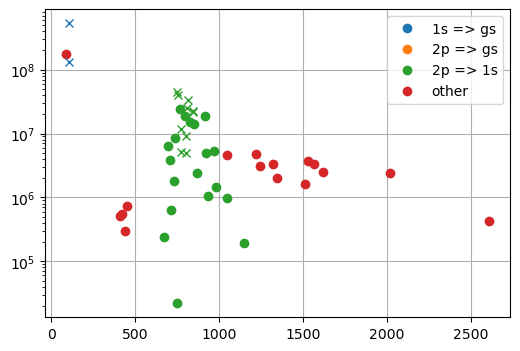

In [4]:
colors = adv_plt.list_colors()
lines_list = RadiativeTransitions.RadiativeTransitions().linesList()

for l in lines_list:
    if( l['from'].startswith('1s') and l['to'] == 'gs' ):
        l['color'] = colors[0]
    elif( l['from'].startswith('2p') and l['to'] == 'gs' ):
        l['color'] = colors[1]
    elif( l['from'].startswith('2p') and l['to'].startswith('1s') ):
        l['color'] = colors[2]
    else:
        l['color'] = colors[3]
    l['marker'] = 'o'

for i in range( len( lines_list ) - 2 ):
    if( lines_list[i+1]['wl'] - lines_list[i]['wl'] < 2 ):
        lines_list[i]['marker'] = 'x'
        lines_list[i+1]['marker'] = 'x'

colors_legend = [ '1s => gs', '2p => gs', '2p => 1s', 'other']

splt.init()

for l in lines_list:
    plt.plot( l['wl'], l['A'], color=l['color'], marker = l['marker'] )
for col, leg in zip( colors, colors_legend ):
    plt.plot( [], [], 'o', color=col, label=leg )

plt.legend()
plt.yscale('log')

lines_selected = [ l for l in lines_list if l['marker'] == 'o' and l['color'] == colors[2] ]
wls_selected = [ l['wl'] for l in lines_selected ]

In [5]:
def gauss(x, H, A, x0, sigma):
    return H + A / np.sqrt(2 * np.pi) / sigma * np.exp(-(x - x0)**2 / (2 * sigma**2))


def compute_densities_poly( wl, int, limit, plot = False ):
    densities = []
    offset = -2
    
    for l in lines_selected:
        idx_where = np.where( wl > l['wl'] + offset + 0.5 )[0]
        if( len( idx_where ) < 1 ):
            continue
        idx = np.min( idx_where )
        idx_max = np.argmax( int[idx-3:idx+4] ) + idx - 3
        if( int[idx_max] < limit ):
            continue

        p = np.polyfit( wl[idx_max-2:idx_max+3], int[idx_max-2:idx_max+3], 2 )
        if( plot ):
            xs = np.linspace( wl[idx_max-2], wl[idx_max+2], 100 )
            plt.plot( xs, np.polyval( p, xs ) )

        densities.append(
            { 'level': l['from'], 'density': np.polyval( p, - p[1] / p[0] / 2 ) / l['A'], 'wl': l['wl'] }
        )
    return densities


def compute_densities( wl, int, limit, plot = False, delta = 4 ):
    densities = []
    offset = -2
    
    for l in lines_selected:
        idx_where = np.where( wl > l['wl'] + offset + 0.5 )[0]
        if( len( idx_where ) < 1 ):
            continue
        idx = np.min( idx_where )
        idx_max = np.argmax( int[idx-3:idx+4] ) + idx - 3
        if( int[idx_max] < limit ):
            continue

        delta = delta
        try:
            p, _ = curve_fit(gauss, wl[idx_max-delta:idx_max+delta+1], int[idx_max-delta:idx_max+delta+1],
                            p0=[ 0, int[idx_max], l['wl'] + offset, 1 ])
        except RuntimeError:
            continue
        
        if( plot ):
            xs = np.linspace( wl[idx_max-2], wl[idx_max+2], 100 )
            plt.plot( xs, gauss( xs, *p ) )
        
        densities.append(
            { 'level': l['from'], 'density': p[1] / l['A'], 'wl': l['wl'] }
        )
    return densities

In [6]:
calib_spectrum = pd.read_csv('CalibrationData/Calib_20250204_FCUVIR600.csv', index_col = False).to_dict('list')
print( calib_spectrum.keys() )

dict_keys(['wl', 'f_W/m2*s', 'f_normalized'])


In [7]:
lv = Levels.Levels()

C:\Users\zampi\AppData\Local\Temp\ipykernel_9164\2747136568.py:44: OptimizeWarning: Covariance of the parameters could not be estimated
  p, _ = curve_fit(gauss, wl[idx_max-delta:idx_max+delta+1], int[idx_max-delta:idx_max+delta+1],


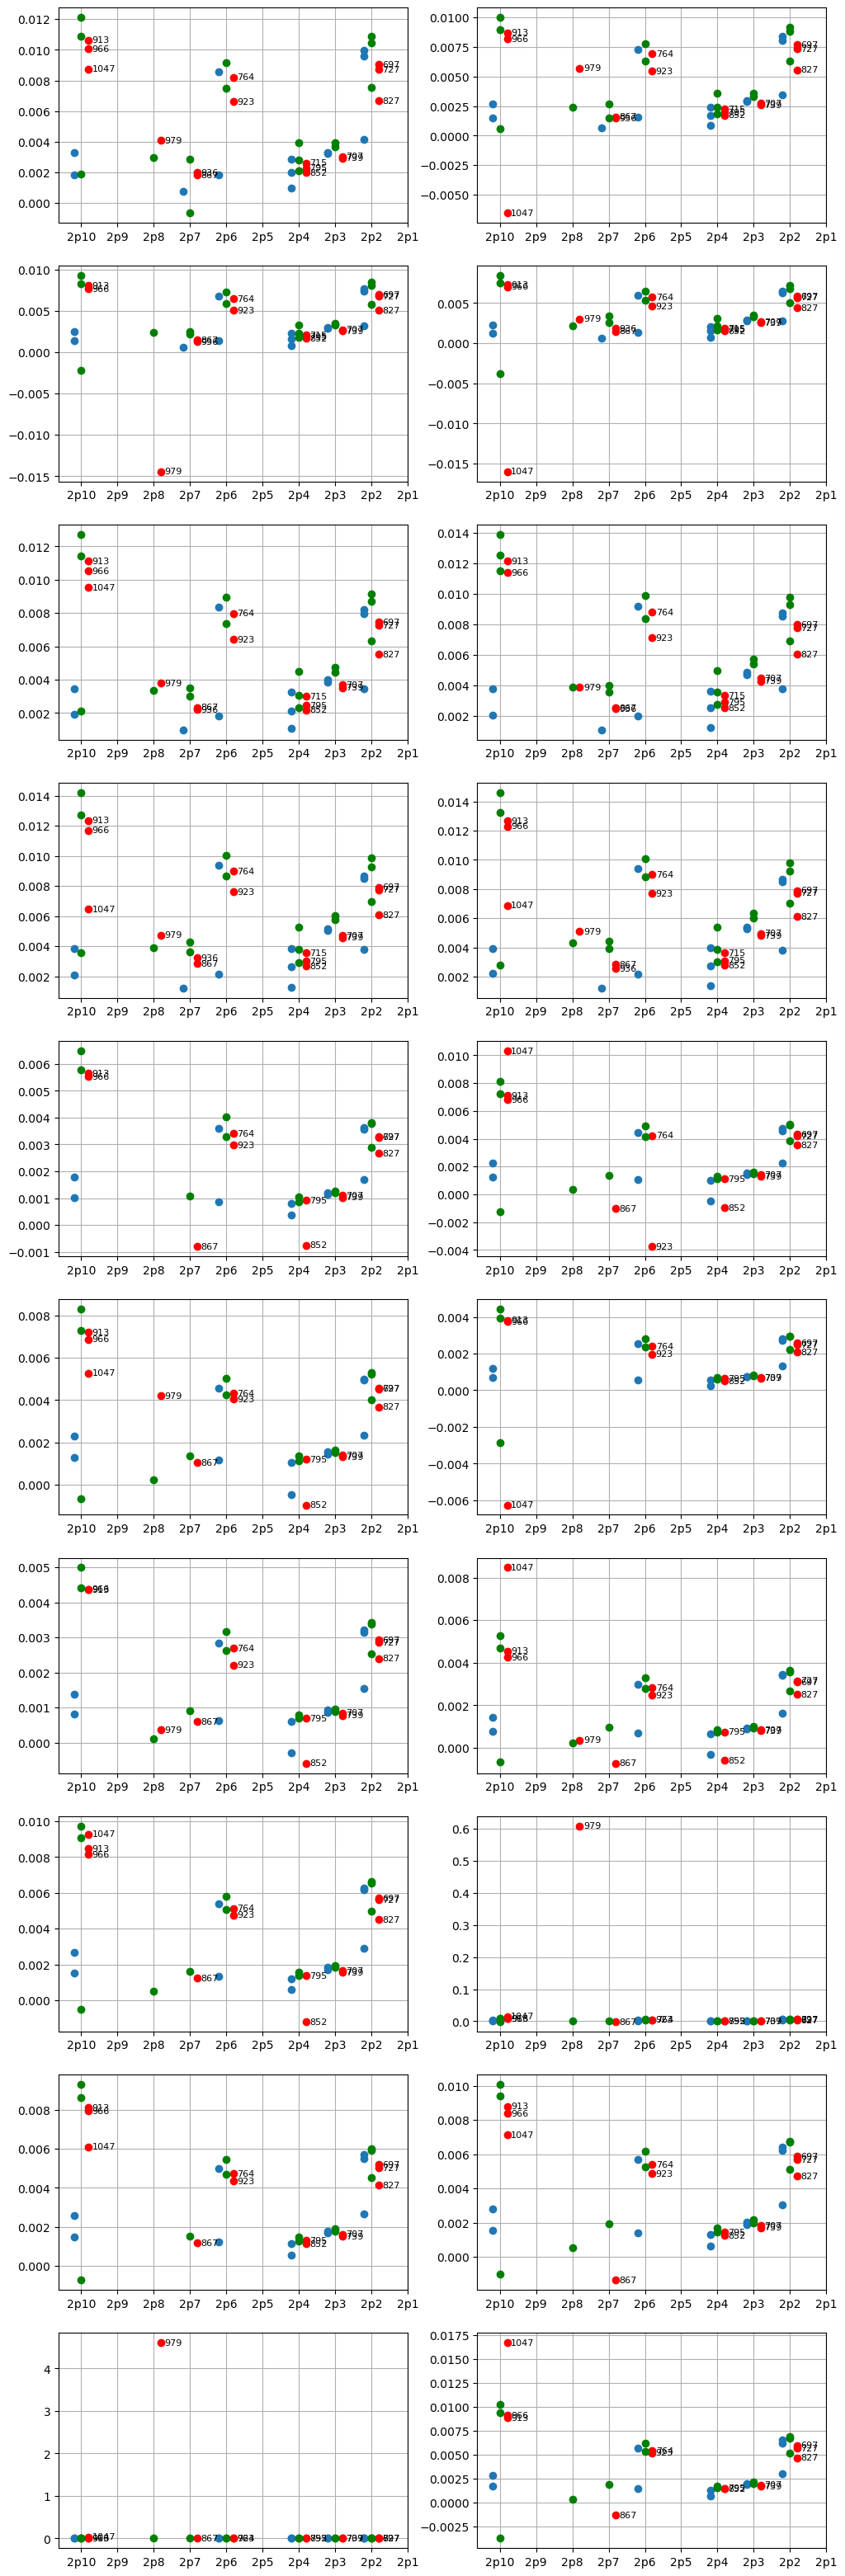

In [8]:
splt.init_bytot( len( data ), cols = 2 )
for d in data:
    # Find the peaks and fit
    offset = -2
    baseline = np.mean( d['avantes']['int'][:40] )


    # Interp line by line
    d['est_densities'] = compute_densities( d['avantes']['wl'], d['avantes']['int'] - baseline, baseline )

    d['calib_int'] = ( d['avantes']['int'] - baseline ) * np.interp( d['avantes']['wl'], calib_spectrum['wl'], calib_spectrum['f_normalized'] )

    d['est_densities_calib_poly'] = compute_densities_poly( d['avantes']['wl'], d['calib_int'], baseline )

    d['est_densities_calib'] = compute_densities( d['avantes']['wl'], d['calib_int'], baseline )

    # d['calib_int_b'] = ( d['avantes']['int'] ) * np.interp( d['avantes']['wl'], calib_spectrum['wl'], calib_spectrum['f_normalized'] )

    # d['est_densities_calib_b'] = compute_densities( d['avantes']['wl'], d['calib_int_b'] - np.mean( d['calib_int_b'][:40] ), baseline )


    splt.next()
    plt.plot(
        [ lv.ID( i['level'] ) - 0.2 for i in d['est_densities'] ],
        [ i['density'] for i in d['est_densities'] ],
        'o'
    )

    plt.plot(
        [ lv.ID( i['level'] ) + 0.2 for i in d['est_densities_calib'] ],
        [ i['density'] for i in d['est_densities_calib'] ],
        'ro'
    )

    plt.plot(
        [ lv.ID( i['level'] ) for i in d['est_densities_calib_poly'] ],
        [ i['density'] for i in d['est_densities_calib_poly'] ],
        'go'
    )


    for i in d['est_densities_calib']:
        plt.text(
            lv.ID( i['level'] ) + 0.3,
            i['density'],
            f"{i['wl']:.0f}",
            va = 'center',
            fontsize = 8
        )

    plt.xticks( np.arange( 5, 15 ), [ lv.name( i ) for i in range( 5,15 ) ])

C:\Users\zampi\AppData\Local\Temp\ipykernel_9164\2747136568.py:44: OptimizeWarning: Covariance of the parameters could not be estimated
  p, _ = curve_fit(gauss, wl[idx_max-delta:idx_max+delta+1], int[idx_max-delta:idx_max+delta+1],
C:\Users\zampi\AppData\Local\Temp\ipykernel_9164\2747136568.py:44: OptimizeWarning: Covariance of the parameters could not be estimated
  p, _ = curve_fit(gauss, wl[idx_max-delta:idx_max+delta+1], int[idx_max-delta:idx_max+delta+1],


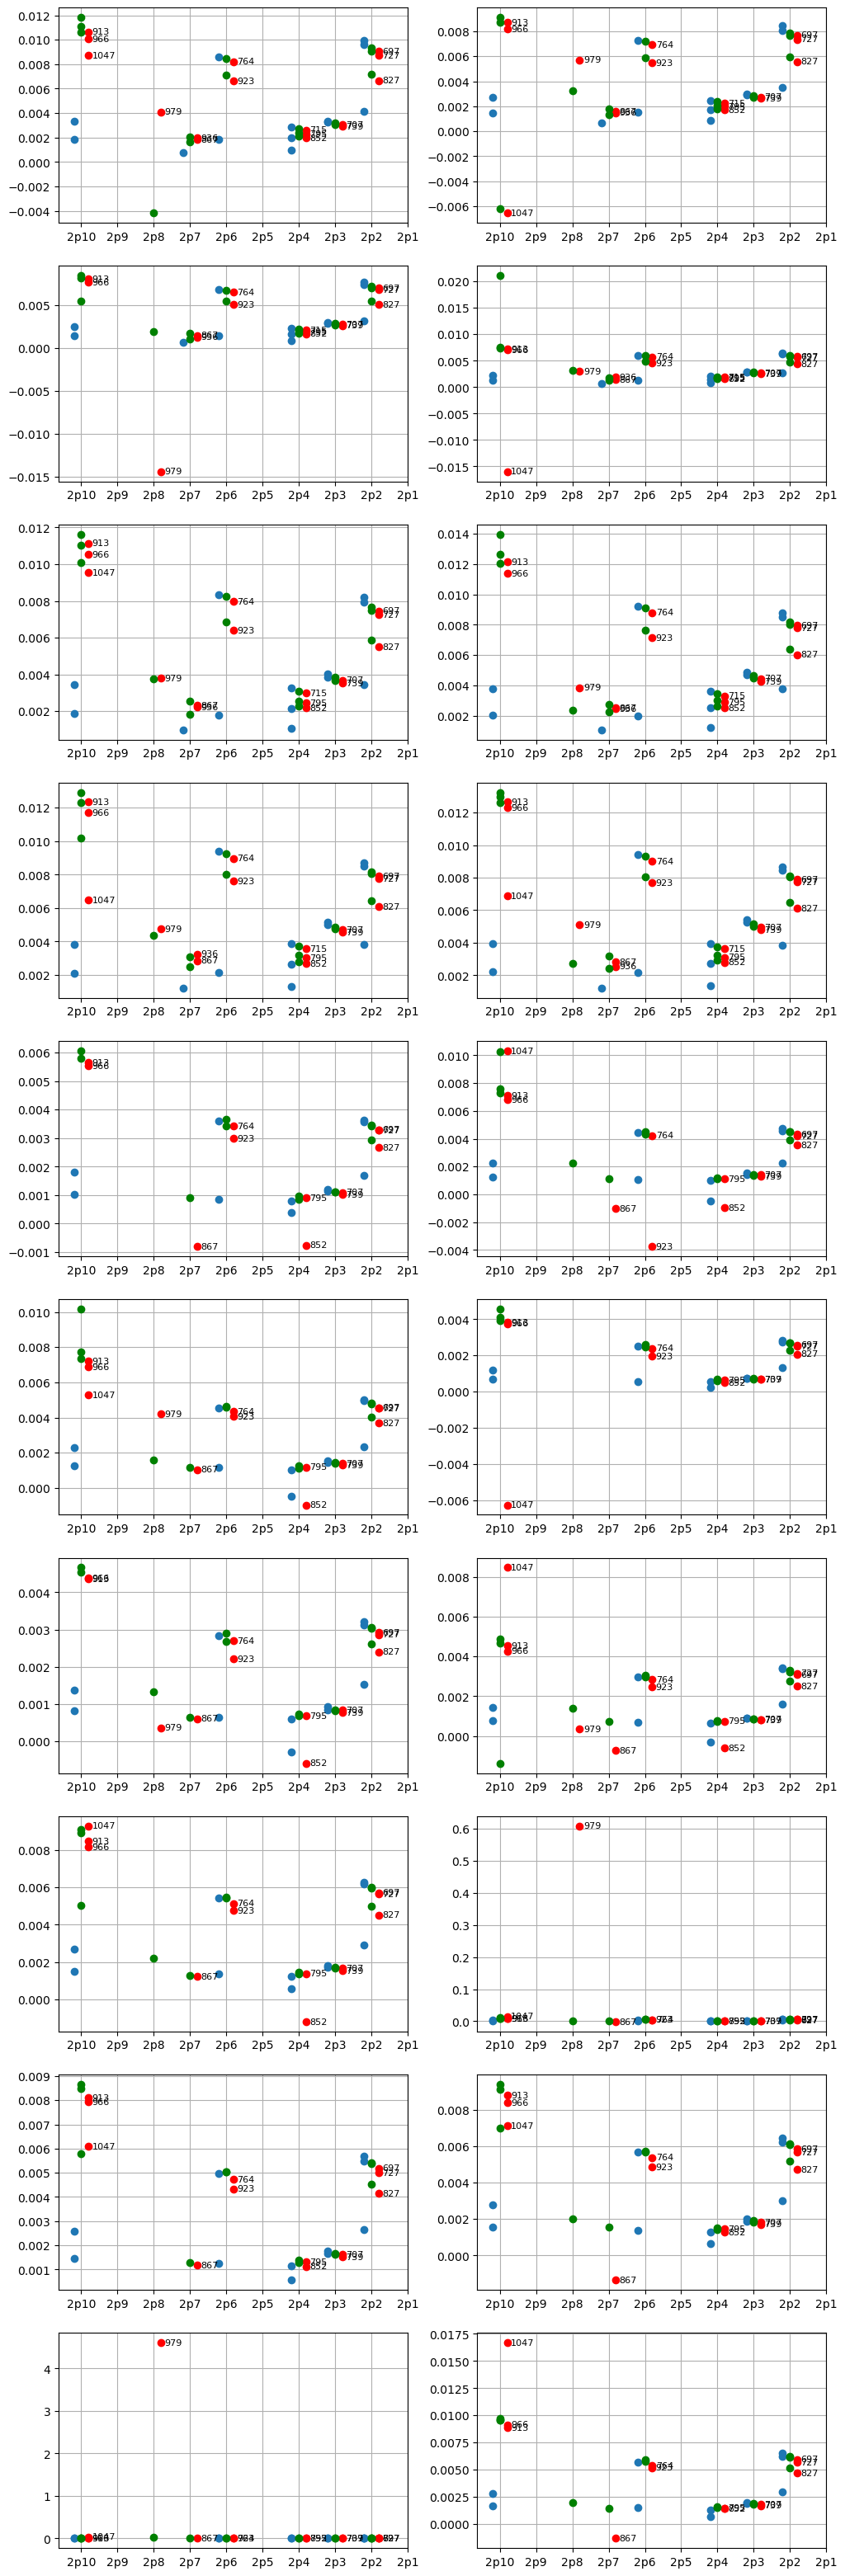

In [9]:
splt.init_bytot( len( data ), cols = 2 )
for d in data:
    # Find the peaks and fit
    offset = -2
    baseline = np.mean( d['avantes']['int'][:40] )


    # Interp line by line
    d['est_densities'] = compute_densities( d['avantes']['wl'], d['avantes']['int'] - baseline, baseline )

    d['calib_int'] = ( d['avantes']['int'] - baseline ) * np.interp( d['avantes']['wl'], calib_spectrum['wl'], calib_spectrum['f_normalized'] )

    d['est_densities_calib_highdelta'] = compute_densities( d['avantes']['wl'], d['calib_int'], baseline, delta = 8 )

    d['est_densities_calib'] = compute_densities( d['avantes']['wl'], d['calib_int'], baseline )

    # d['calib_int_b'] = ( d['avantes']['int'] ) * np.interp( d['avantes']['wl'], calib_spectrum['wl'], calib_spectrum['f_normalized'] )

    # d['est_densities_calib_b'] = compute_densities( d['avantes']['wl'], d['calib_int_b'] - np.mean( d['calib_int_b'][:40] ), baseline )


    splt.next()
    plt.plot(
        [ lv.ID( i['level'] ) - 0.2 for i in d['est_densities'] ],
        [ i['density'] for i in d['est_densities'] ],
        'o'
    )

    plt.plot(
        [ lv.ID( i['level'] ) + 0.2 for i in d['est_densities_calib'] ],
        [ i['density'] for i in d['est_densities_calib'] ],
        'ro'
    )

    plt.plot(
        [ lv.ID( i['level'] ) for i in d['est_densities_calib_highdelta'] ],
        [ i['density'] for i in d['est_densities_calib_highdelta'] ],
        'go'
    )


    for i in d['est_densities_calib']:
        plt.text(
            lv.ID( i['level'] ) + 0.3,
            i['density'],
            f"{i['wl']:.0f}",
            va = 'center',
            fontsize = 8
        )

    plt.xticks( np.arange( 5, 15 ), [ lv.name( i ) for i in range( 5,15 ) ])